# Only visualize on validation set
## Dependencies

In [ ]:
import pickle
import yaml
import numpy as np
import pandas as pd
import hdbscan
from scipy.stats import mode

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.mixture import GaussianMixture

import umap

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as mpatches
from matplotlib.cm import get_cmap
import matplotlib.gridspec as gridspec

In [5]:
L = 3000 # original length
tp = 1
l = int(L/tp) # after patch

N = int(90000/L)
D = 192
sample_frequency = 2

with open("/home/rguo_hpc/myfolder/mocap/configs/sdannce/fmr1.yaml") as f:
    split = yaml.safe_load(f)
    
# load original data 
with open("/home/rguo_hpc/myfolder/data/sdannce/data_fmr1.pkl", 'rb') as file:
    result = pickle.load(file)

In [6]:
feats = np.load("/home/rguo_hpc/myfolder/mocap/outputs/sdannce/fmr1/50/representations/mae_sdannce_val.npy")[:, 25:3025][:,::sample_frequency]
print(feats.shape)
total_seq = len(feats)

(180, 1500, 192)


In [7]:
# load original data 
with open("/home/rguo_hpc/myfolder/data/sdannce/data_fmr1.pkl", 'rb') as file:
    result = pickle.load(file)

for mouse in result.keys():     # result.keys(): [408, 407, 404, 403, 402, 406, 405, 401]
    num_seq = len(result[mouse]["ratid"])
    ratgen  = result[mouse]["ratgen"]
    result[mouse]["ratgen"] = [ratgen for i in range(num_seq * N,)]
    
    ratid = result[mouse]["ratid"][0]
    result[mouse]["ratid"] = [ratid for i in range(num_seq * N,)]
    """
    # llac    
    llac = np.array(result[mouse]["llac"]).reshape(-1, L,)
    if tp > 1:
        grouped_llac = llac.reshape(-1, l, tp) # choose the mode label of each patch 
        result[mouse]["llac"] = mode(grouped_llac, axis=2, keepdims=False).mode.astype(np.uint8)
    else:
        result[mouse]["llac"] = llac
    """
    # hlac
    hlac = result[mouse]["hlac"].reshape(-1, L,)
    if tp > 1:
        grouped_hlac = hlac.reshape(-1, l, 3)
        result[mouse]["hlac"] = mode(grouped_hlac, axis=2, keepdims=False).mode.astype(np.uint8)
    else:
        result[mouse]["hlac"] = hlac
    
    del result[mouse]["m1"]

In [8]:
# Val:  mouse, genotype, hlac, llac
mouse_val, gen_val, hlac_val, llac_val = [], [], [], []
for mouse_id in split["fold_1"]["valid"]:
    mouse_val.append(result[mouse_id]["ratid"])
    gen_val.append(result[mouse_id]["ratgen"])
    hlac_val.append(result[mouse_id]["hlac"])
    llac_val.append(result[mouse_id]["llac"]) 
    
mouse_labels = np.repeat(np.concatenate(mouse_val), l)[::sample_frequency]
gen_labels = np.repeat(np.concatenate(gen_val), l)[::sample_frequency]

hlac_labels = np.concatenate(hlac_val)[:,::sample_frequency]
llac_labels = np.concatenate(llac_val)[:,::sample_frequency]

In [9]:
seq_ids = np.repeat(np.arange(total_seq), int(l/sample_frequency)) # repeat each element l times
frame_ids = np.tile(np.arange(int(l/sample_frequency)), total_seq)

## PCA

In [10]:
pca_components = 32
feats_pca = PCA(n_components=pca_components, random_state=42)
feats_pca_embeddings = feats_pca.fit_transform(feats.reshape(-1, D))
print(feats_pca_embeddings.shape)

feats_cumvar = np.cumsum(feats_pca.explained_variance_ratio_)
print(f"Variance explained by 50 PCs: {feats_cumvar[-1]:.1%}")

(270000, 32)
Variance explained by 50 PCs: 97.4%


## UMAP

In [11]:
reducer = umap.UMAP(n_components=2, n_neighbors=50, min_dist=0.1,  random_state=42, low_memory=True, metric='cosine')
feats_2d = reducer.fit_transform(feats_pca_embeddings.reshape(-1, pca_components))

/home/rguo_hpc/.conda/envs/moseq/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [47]:
np.save("feats_pca_2d_val.npy", feats_2d)

## Cluster

In [15]:
kmeans = KMeans(n_clusters=16, random_state=0, n_init=10, max_iter=200)
labels = kmeans.fit_predict(feats_pca_embeddings.reshape(-1, pca_components))

In [ ]:
gmm = GaussianMixture(n_components=16, random_state=0, max_iter=200)
gmm_labels = gmm.fit_predict(feats_pca_embeddings.reshape(-1, pca_components))

In [12]:
# HDBSCAM
clu = hdbscan.HDBSCAN(min_cluster_size= 1800, min_samples=5, cluster_selection_method="eom",
                      prediction_data=True, cluster_selection_epsilon=0.3).fit(feats_pca_embeddings) # 2000, 0.05
    
print(clu.labels_.max() + 1, (clu.labels_ == -1).mean())

5 0.00707037037037037


In [ ]:
np.save("hdbscan_val.npy", clu)

## Visualization

In [16]:
mapping = {1: "idle", 2: "sniff/head", 3: "groom", 4: "scrunched", 5: "active crouched", 
           6: "reared", 7: "explore ", 8: "locomotion", 9: "fast/error",}
hlac_labels_str = np.vectorize(mapping.get)(hlac_labels.reshape(hlac_labels.size, ))

In [17]:
df = pd.DataFrame({
    'umap_x':       feats_2d[:, 0], 
    'umap_y':       feats_2d[:, 1],
    'cluster':      labels,
    'seq_id':       seq_ids,           # 0..num_sequences
    'frame_idx':    frame_ids,         # 0..1199
    'mouse_label':  mouse_labels,#[frame_ids + seq_ids*l][::sample_frequency],  # broadcast to frame level
    'gen_label':    gen_labels,
    'hlac_label':   hlac_labels_str,
    "hdbscan":      clu.labels_
    
})

In [18]:
def plot_cluster_landscape(df, umap_x='umap_x', umap_y='umap_y', cluster_label = 'cluster', figsize=(14, 6)):
    """
    Left : UMAP colored by cluster
    Right: Bar chart of cluster sizes, sorted largest → smallest
    """
    n_clusters = df[cluster_label].nunique()
    cmap = get_cmap('tab20', n_clusters)
    colors = {c: cmap(i) for i, c in enumerate(sorted(df[cluster_label].unique()))}

    cluster_sizes = df[cluster_label].value_counts().sort_index()
    cluster_pcts  = cluster_sizes / len(df) * 100

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [1.4, 1]})

    # --- Left: UMAP scatter ---
    for c, grp in df.groupby(cluster_label):
        ax1.scatter(grp[umap_x], grp[umap_y], color=colors[c], s=0.3, alpha=0.4, rasterized=True)

    # Annotate each cluster centroid with its ID
    for c, grp in df.groupby(cluster_label):
        cx, cy = grp[umap_x].mean(), grp[umap_y].mean()
        ax1.text(cx, cy, str(c), fontsize=7, fontweight='bold', ha='center', va='center',
                 bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6, lw=0))

    ax1.set_title('UMAP — colored by cluster', fontsize=11)
    ax1.axis('off')

    # --- Right: bar chart sorted by size ---
    sorted_clusters = cluster_sizes.sort_values(ascending=False).index
    bar_colors = [colors[c] for c in sorted_clusters]
    sizes_sorted = cluster_sizes[sorted_clusters]
    pcts_sorted  = cluster_pcts[sorted_clusters]

    bars = ax2.barh(range(len(sorted_clusters)), sizes_sorted.values,
                    color=bar_colors, edgecolor='white', linewidth=0.5)

    # Annotate bars with percentage
    for i, (bar, pct) in enumerate(zip(bars, pcts_sorted)):
        ax2.text(bar.get_width() + sizes_sorted.max() * 0.01, i,
                 f'{pct:.1f}%', va='center', fontsize=8, color='#444')

    ax2.set_yticks(range(len(sorted_clusters)))
    ax2.set_yticklabels([f'{c}' for c in sorted_clusters], fontsize=8)
    ax2.invert_yaxis()
    ax2.set_xlabel('Number of frames')
    ax2.set_title('Cluster sizes', fontsize=11)
    ax2.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    #plt.savefig('cluster_landscape.pdf', dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
plot_cluster_landscape(df,'umap_x',  'umap_y', 'hdbscan')

/tmp/ipykernel_2121170/731231859.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20', n_clusters)


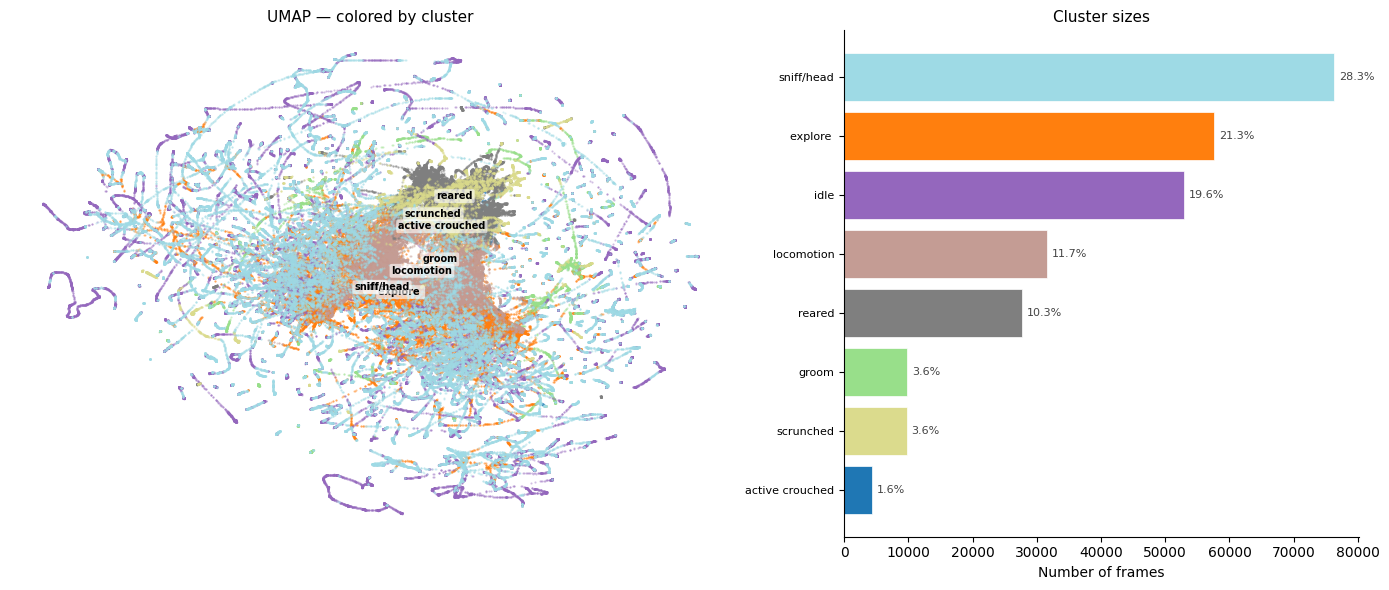

In [52]:
plot_cluster_landscape(df,'umap_x',  'umap_y', 'hdbscan')